In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scienceplots
import nanonets
import matplotlib.cm as cm
import matplotlib.colors as mcolors

from nanonets.utils.signals import extract_harmonic_features, get_phase_lag, compute_thd
from scipy.interpolate import UnivariateSpline

plt.style.use(["science","bright","grid"])

N_PERIODS       = 100
N_EQ_PERIODS    = 40
SAMPLE_P_PERIOD = 40
SELF_CAP        = 0.0

topo = {"Nx": 1, "Ny": 1, "electrode_type" : ['constant','constant']}
sim = nanonets.Simulation(topo, SELF_CAP)
v_base = sim.electrostatic.get_charging_energies()[0]*1e-3

In [37]:
AMPLITUDE_MULT  = [1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
FREQ_LIST       = np.round(np.logspace(0,4,30),2)
data_raw        = {amp_mult : {f0 : pd.read_csv(f"../../data/raw/time_dependent/set_freq_amp/set_amp{amp_mult*v_base:.3f}_f0{f0:.2f}_self_cap{SELF_CAP:.2f}.csv").iloc[N_EQ_PERIODS*SAMPLE_P_PERIOD:,:]
                               for f0 in FREQ_LIST} for amp_mult in AMPLITUDE_MULT}

### Average Signal along Periods

In [38]:
t = {f0 : np.arange(5 * SAMPLE_P_PERIOD)*(data_raw[1][f0]['t'].values[1] - data_raw[1][f0]['t'].values[0]) * 1e9 for f0 in FREQ_LIST}
x = {amp : {f0 : np.mean(data_raw[amp][f0]['E0'].values.reshape((12, 5 * SAMPLE_P_PERIOD)), axis=0)*1000 for f0 in FREQ_LIST} for amp in AMPLITUDE_MULT}
y = {amp : {f0 : np.mean(data_raw[amp][f0]['Observable'].values.reshape((12, 5 * SAMPLE_P_PERIOD)), axis=0)*1e-9 for f0 in FREQ_LIST} for amp in AMPLITUDE_MULT}
y_e = {amp : {f0 : np.sqrt(np.sum(data_raw[amp][f0]['Error'].values.reshape((12, 5 * SAMPLE_P_PERIOD))**2, axis=0))*1e-9 / ((N_PERIODS - N_EQ_PERIODS) // 5) for f0 in FREQ_LIST} for amp in AMPLITUDE_MULT}
y_d = {amp : {f0 : np.mean(data_raw[amp][f0]['Displacement'].values.reshape((12, 5 * SAMPLE_P_PERIOD)), axis=0)*1e-9 for f0 in FREQ_LIST} for amp in AMPLITUDE_MULT}
rms = {amp : np.array([np.std(y[amp][f0] + y_d[amp][f0])/(amp*1e-3) for f0 in FREQ_LIST]) for amp in AMPLITUDE_MULT}
phi = {amp : np.array([get_phase_lag(y[amp][f0] + y_d[amp][f0], x[amp][f0]) for f0 in FREQ_LIST]) for amp in AMPLITUDE_MULT}
h_f = {amp : {f0 : extract_harmonic_features(y[amp][f0] + y_d[amp][f0], [1,2,3,4,5,6,7,8,9], 5, mode='abs') for f0 in FREQ_LIST} for amp in AMPLITUDE_MULT}

### Signal Admittance and Phase, i.e. Bose Plot

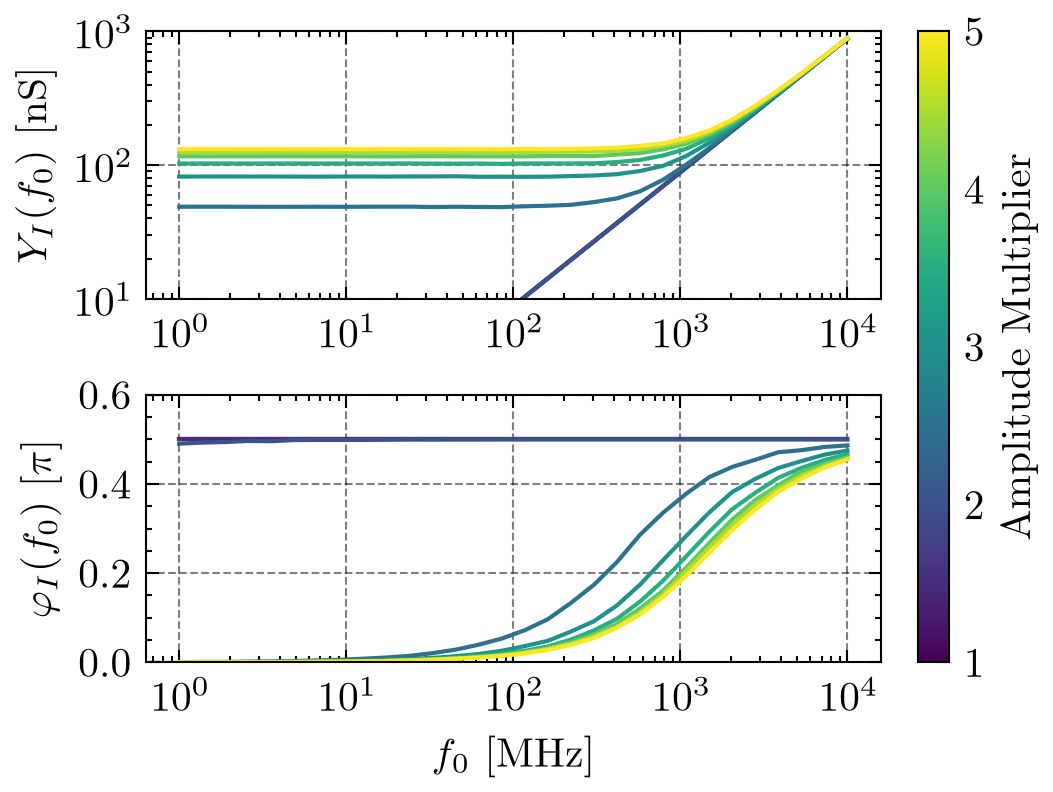

In [40]:
fig = plt.figure(dpi=300, layout='constrained')
ax1 = fig.add_subplot(2, 1, 1)
ax2 = fig.add_subplot(2, 1, 2)

norm = mcolors.Normalize(vmin=min(AMPLITUDE_MULT), vmax=max(AMPLITUDE_MULT))
cmap = cm.viridis

for amp in AMPLITUDE_MULT:

    ax1.plot(FREQ_LIST, rms[amp], color=cmap(norm(amp)))
    ax2.plot(FREQ_LIST, phi[amp], color=cmap(norm(amp)))

_ = ax1.set_xscale('log')
_ = ax1.set_yscale('log')
_ = ax2.set_xscale('log')

_ = ax1.set_ylim(10,1000)
_ = ax2.set_ylim(0,0.6)

_ = ax1.set_ylabel("$Y_{I}(f_0)$ [nS]")
_ = ax2.set_ylabel("$\\varphi_{I}(f_0)~[\\pi]$")
_ = ax2.set_xlabel('$f_0~[\\mathrm{MHz}]$')

sm = cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm, ax=[ax1, ax2], location='right')
cbar.set_label('Amplitude Multiplier')

### Cutoff Frequency

In [ ]:
cross = []
for amp in AMPLITUDE_MULT:
    x_vals  = np.array(FREQ_LIST)
    y_1     = np.array([np.std(y[amp][f0]) for f0 in FREQ_LIST])
    y_2     = np.array([np.std(y_d[amp][f0]) for f0 in FREQ_LIST])
    y_diff  = y_1 - y_2
    spline  = UnivariateSpline(x_vals, y_diff, s=0)
    pts     = spline.roots()
    if len(pts) != 0:
        cross.append(pts[0])
    else:
        cross.append(np.nan)
cross = np.array(cross)

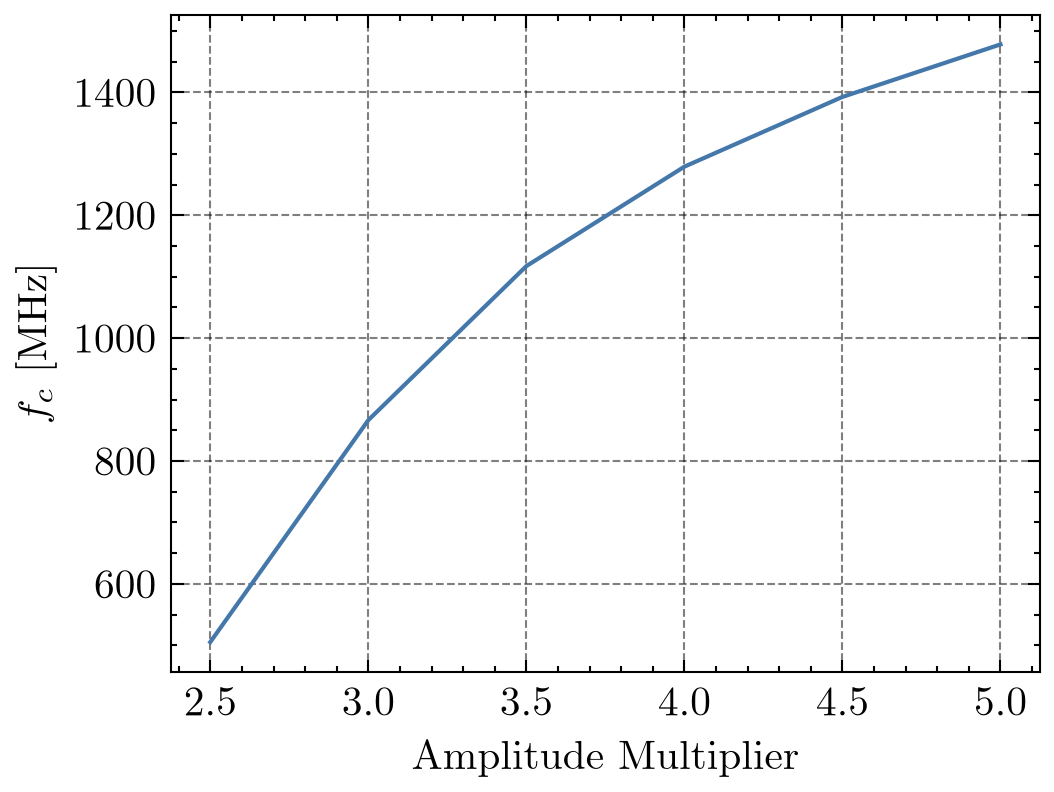

In [71]:
fig = plt.figure(dpi=300, layout='constrained')
ax = fig.add_subplot()
_ = ax.plot(AMPLITUDE_MULT, cross)
_ = ax.set_xlabel('Amplitude Multiplier')
_ = ax.set_ylabel('$f_c~[\\mathrm{MHz}]$')

### Total Harmonic Distortion

In [86]:
thd = {amp : [compute_thd(h_f[amp][f0]) for f0 in FREQ_LIST] for amp in AMPLITUDE_MULT}

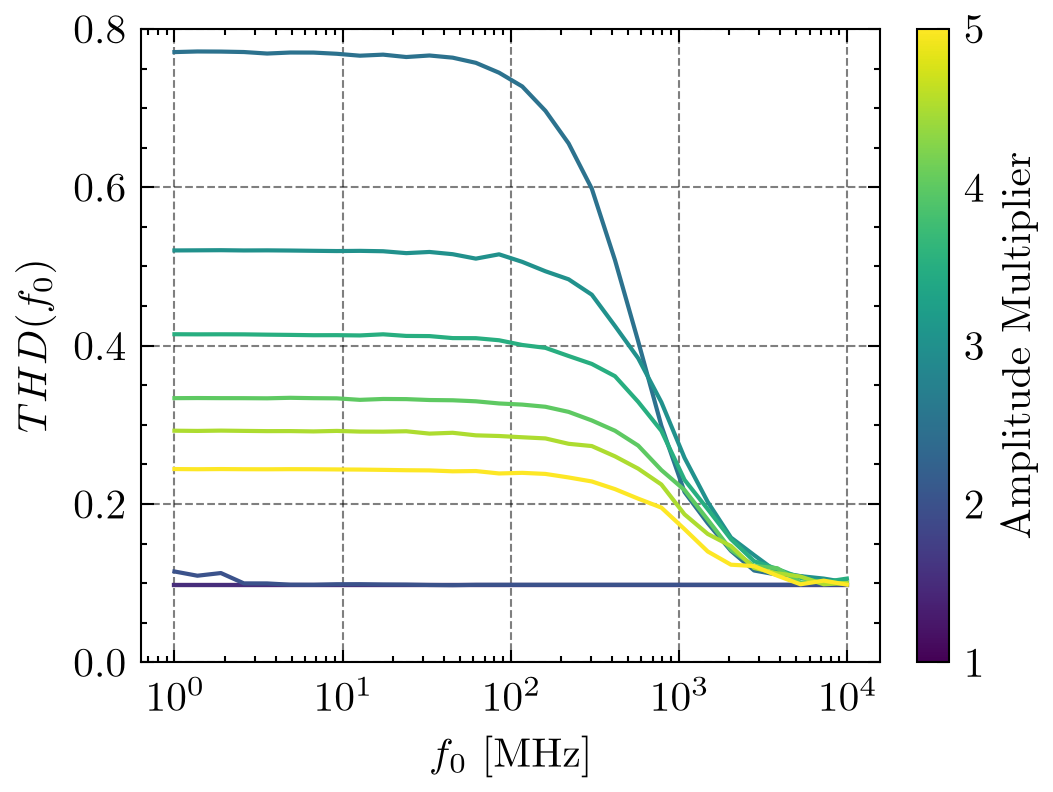

In [117]:
fig = plt.figure(dpi=300, layout='constrained')
ax  = fig.add_subplot()
norm = mcolors.Normalize(vmin=min(AMPLITUDE_MULT), vmax=max(AMPLITUDE_MULT))
cmap = cm.viridis

for i, amp in enumerate(AMPLITUDE_MULT):

    ax.plot(FREQ_LIST, thd[amp], color=cmap(norm(amp)))

_ = ax.set_xscale('log')
_ = ax.set_ylim(0,0.8)

_ = ax.set_ylabel("$THD(f_0)$")
_ = ax.set_xlabel('$f_0~[\\mathrm{MHz}]$')

sm = cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm, ax=ax, location='right')
cbar.set_label('Amplitude Multiplier')

Best Values
- $f_0 = 500$ MHz
- $a = 3$

### Response and Frequency Analysis

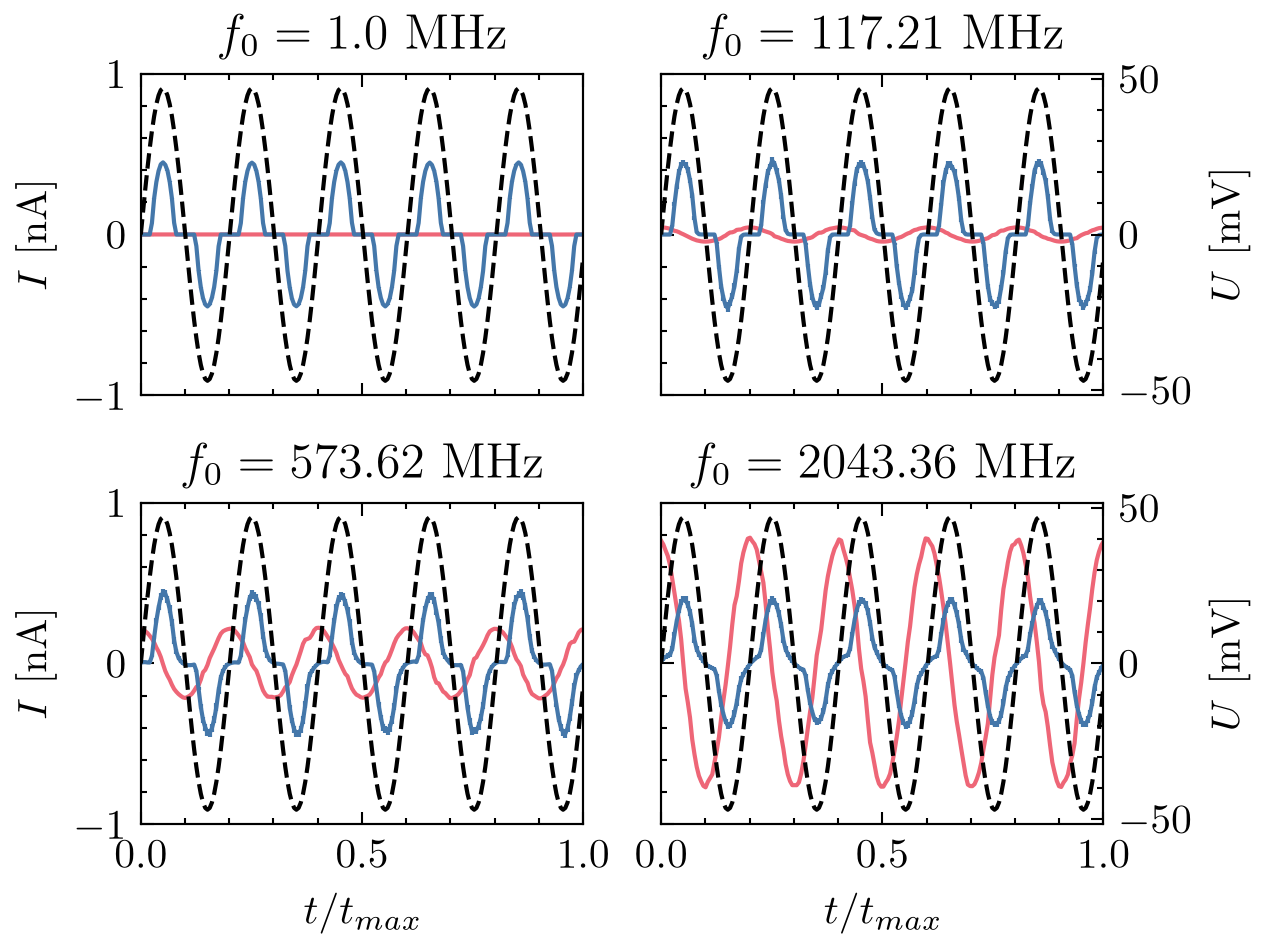

In [77]:
amp = 3
f0s = [FREQ_LIST[0], FREQ_LIST[15], FREQ_LIST[2*len(FREQ_LIST)//3], FREQ_LIST[-6]]
fig, axes = plt.subplots(2, 2, sharex=True, sharey=True, dpi=300, layout='constrained')
fig.set_figheight(fig.get_figheight()*1.2)
fig.set_figwidth(fig.get_figwidth()*1.2)

ax2_first = None

for i, f0 in enumerate(f0s):
    ax = axes.flat[i]
    col = i % 2
    
    if ax2_first is None:
        ax2 = ax.twinx()
        ax2_first = ax2
    else:
        ax2 = ax.twinx()
        ax2.sharey(ax2_first)

    if col == 0:
        ax2.tick_params(axis='y', which='both', labelright=False, right=False)
    else:
        ax2.set_ylabel("$U~[\\mathrm{mV}]$")

    t_norm = t[f0] / t[f0].max()

    ax2.plot(t_norm, x[amp][f0], color='black', ls='--')
    ax2.grid(False)

    ax.errorbar(t_norm, y[amp][f0], y_e[amp][f0])
    ax.plot(t_norm, y_d[amp][f0])
    ax.grid(False)
    ax.set_title(f"$f_0 = {f0}~\\mathrm{{MHz}}$")

_ = axes[0, 0].set_xlim(0, 1)
_ = axes[0, 0].set_ylim(-1, 1)
_ = axes[0, 0].set_ylabel("$I~[\\mathrm{nA}]$")
_ = axes[1, 0].set_ylabel("$I~[\\mathrm{nA}]$")
_ = axes[1, 1].set_xlabel("$t / t_{max}$")
_ = axes[1, 0].set_xlabel("$t / t_{max}$")

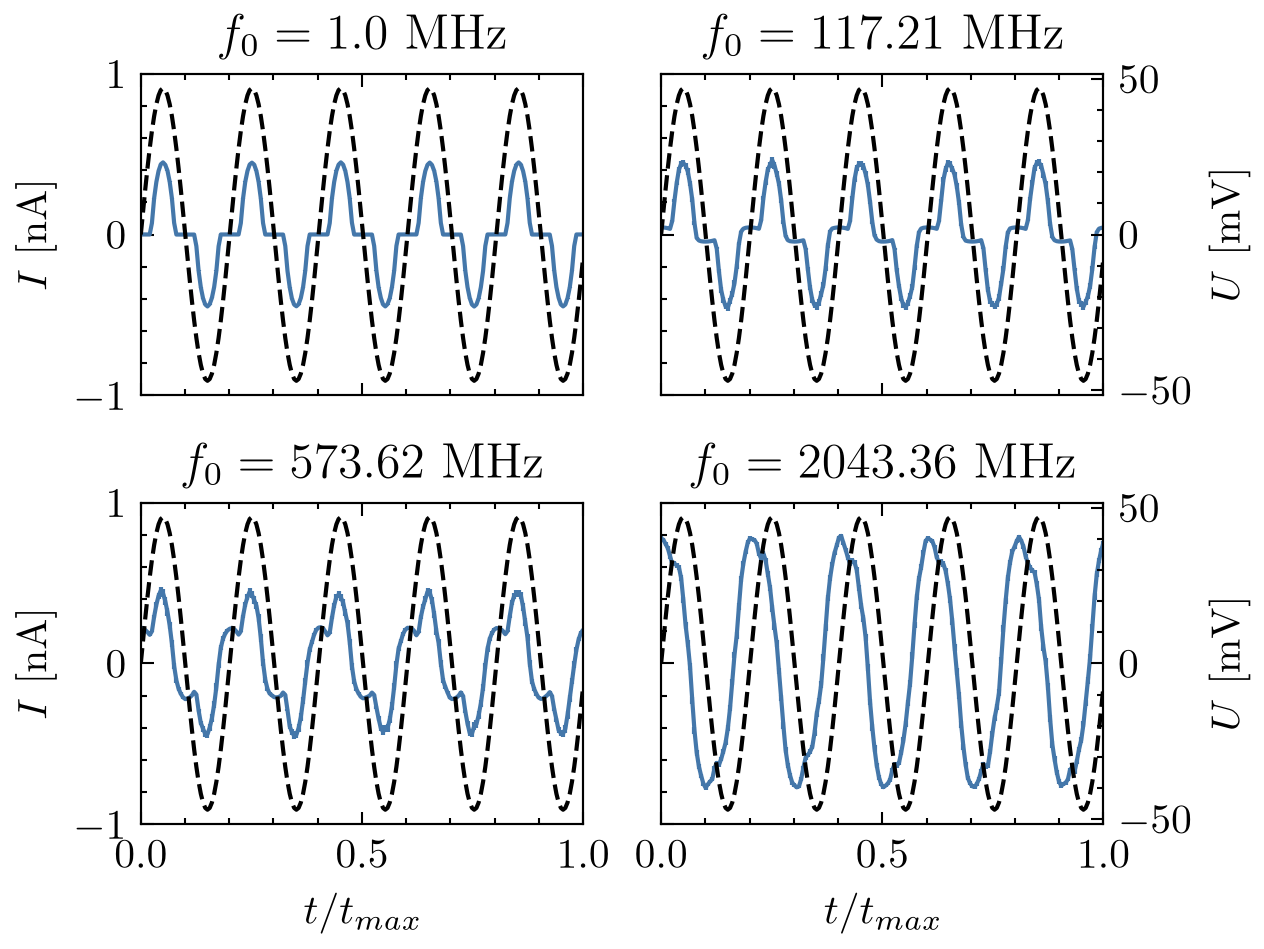

In [78]:
fig, axes = plt.subplots(2, 2, sharex=True, sharey=True, dpi=300, layout='constrained')
fig.set_figheight(fig.get_figheight()*1.2)
fig.set_figwidth(fig.get_figwidth()*1.2)

ax2_first = None

for i, f0 in enumerate(f0s):
    ax = axes.flat[i]
    col = i % 2
    
    if ax2_first is None:
        ax2 = ax.twinx()
        ax2_first = ax2
    else:
        ax2 = ax.twinx()
        ax2.sharey(ax2_first)

    if col == 0:
        ax2.tick_params(axis='y', which='both', labelright=False, right=False)
    else:
        ax2.set_ylabel("$U~[\\mathrm{mV}]$")

    t_norm = t[f0] / t[f0].max()

    ax2.plot(t_norm, x[amp][f0], color='black', ls='--')
    ax2.grid(False)

    ax.errorbar(t_norm, y[amp][f0] + y_d[amp][f0], y_e[amp][f0])
    ax.grid(False)
    ax.set_title(f"$f_0 = {f0}~\\mathrm{{MHz}}$")

_ = axes[0, 0].set_xlim(0, 1)
_ = axes[0, 0].set_ylim(-1, 1)
_ = axes[0, 0].set_ylabel("$I~[\\mathrm{nA}]$")
_ = axes[1, 0].set_ylabel("$I~[\\mathrm{nA}]$")
_ = axes[1, 1].set_xlabel("$t / t_{max}$")
_ = axes[1, 0].set_xlabel("$t / t_{max}$")

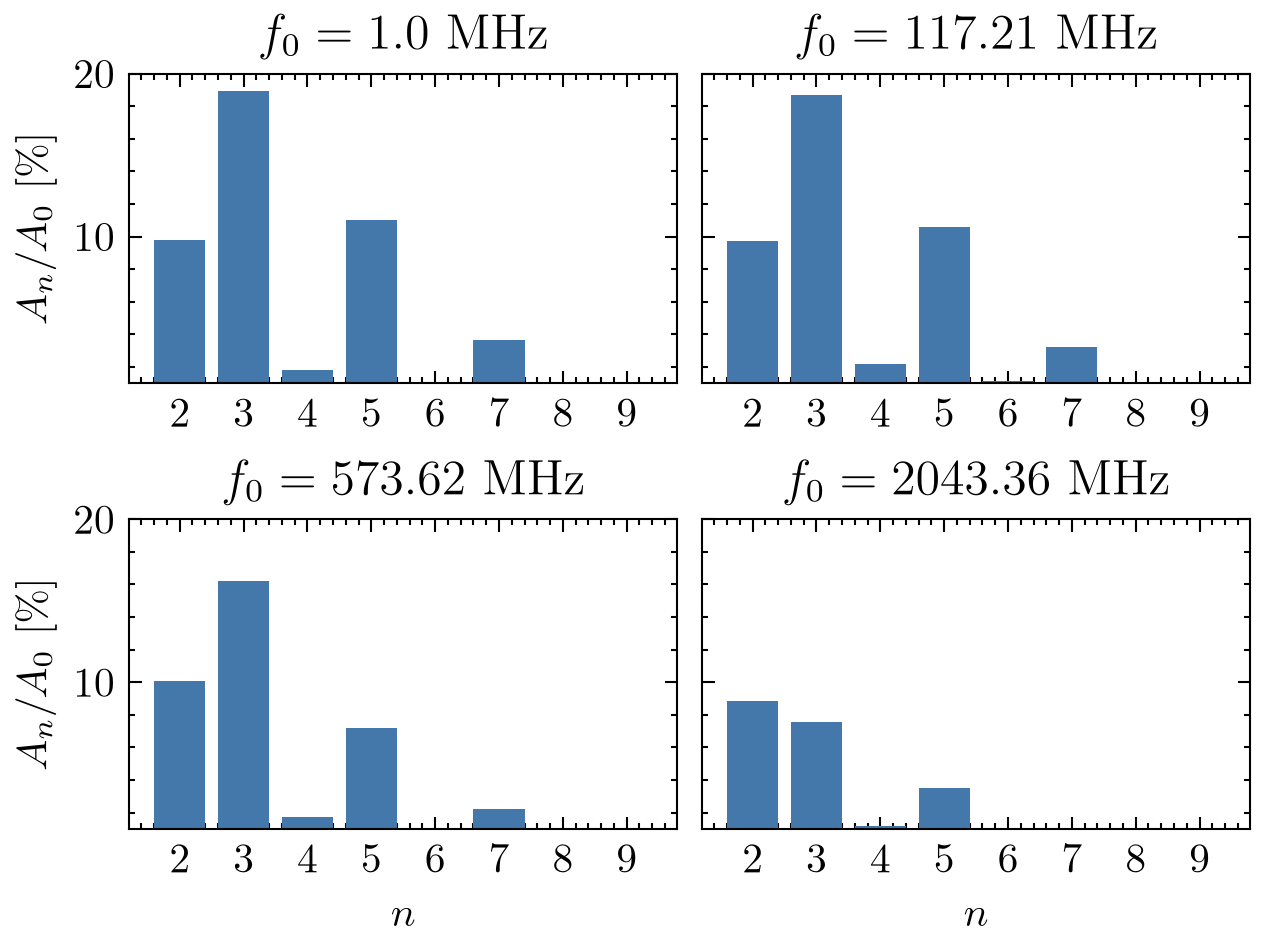

In [ ]:
fig, axes = plt.subplots(2, 2, sharex=False, sharey=True, dpi=300, layout='constrained')
fig.set_figheight(fig.get_figheight()*1.2)
fig.set_figwidth(fig.get_figwidth()*1.2)

for i, f0 in enumerate(f0s):
    ax = axes.flat[i]
    ax.bar([2,3,4,5,6,7,8,9], 100*h_f[amp][f0][1:]/h_f[amp][f0][0])
    ax.set_xticks([2,3,4,5,6,7,8,9])   

    ax.grid(False)
    ax.set_title(f"$f_0 = {f0}~\\mathrm{{MHz}}$")
    ax.set_ylim(1,20)

_ = axes[0, 0].set_ylabel("$A_n / A_0~[\\%]$")
_ = axes[1, 0].set_ylabel("$A_n / A_0~[\\%]$")
_ = axes[1, 1].set_xlabel("$n$")
_ = axes[1, 0].set_xlabel("$n$")